# 06.1 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/01-what-is-unsupervised/solutions.ipynb)

In [1]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

In [2]:
import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

snapshot = sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)    # 2011-12-10
rfm = sales.groupby("Customer ID").agg(
    recency=("InvoiceDate", lambda d: (snapshot - d.max()).days),
    frequency=("Invoice", "nunique"),
    monetary=("Revenue", "sum"))
print(f"{len(sales):,} rows, {len(rfm):,} customers, snapshot {snapshot.date()}")

392,693 rows, 4,338 customers, snapshot 2011-12-10


In [3]:
from sklearn.preprocessing import StandardScaler

rfm_log = np.log1p(rfm)                         # tame the long right tails
X = StandardScaler().fit_transform(rfm_log)      # mean 0, std 1 per column
print("X shape:", X.shape)

X shape: (4338, 3)


## Exercise 1

In [4]:
from sklearn.cluster import KMeans

for k in [3, 4, 5]:
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    prof = rfm.assign(g=labels).groupby("g").agg(n=("recency", "size"), R=("recency", "mean"),
                                                  F=("frequency", "mean"), M=("monetary", "mean"))
    print(f"--- k = {k}")
    print(prof.sort_values("M", ascending=False).round(1).to_string(index=False))

--- k = 3
   n     R    F      M
 743  13.8 13.5 7925.6
1679  46.0  3.5 1379.2
1916 162.8  1.3  356.4
--- k = 4
   n     R    F      M
 699  11.4 13.9 8194.3
1178  70.0  4.1 1814.5
 826  17.3  2.2  555.8
1635 180.3  1.3  344.2
--- k = 5
   n     R    F       M
 292   9.2 22.3 15231.5
 973  20.9  6.3  2431.6
1043 106.9  2.9  1351.9
 806  22.8  1.8   421.7
1224 201.4  1.2   264.5


Going from 3 to 4, the middle group (about 1,680 customers, 3.5 orders) splits into a **recent, low-spend** group (826 customers who bought lately but only about twice) and an **older group of regulars** who spend more (1,178 customers), with some of the bottom group's more recent customers joining them. The top group (743 → 699 frequent, high spenders) and the bottom group (one order, long ago) barely change.

Going to 5, the top group splits off a small core of 292 "super-champions" (22 orders and about £15,000 each on average).

Groups that survive every *k* are the most trustworthy.

## Exercise 2

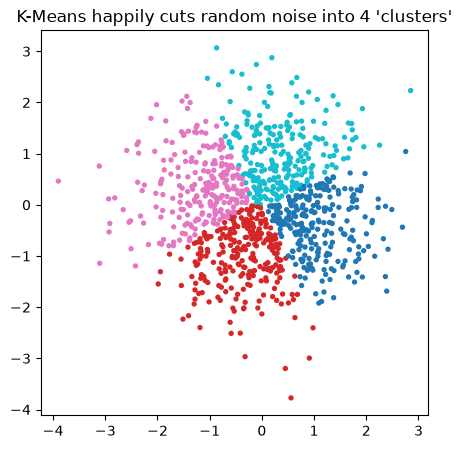

[252 258 241 249]


In [5]:
noise = np.random.default_rng(0).normal(size=(1000, 2))
labels = KMeans(n_clusters=4, n_init=10, random_state=42).fit_predict(noise)

plt.figure(figsize=(5, 5))
plt.scatter(noise[:, 0], noise[:, 1], c=labels, s=8, cmap="tab10")
plt.title("K-Means happily cuts random noise into 4 'clusters'")
plt.show()
print(np.bincount(labels))

K-Means never refuses. It slices the round blob of noise into four pie wedges of similar size. **An algorithm returning clusters is not evidence that clusters exist.** That is why you check stability, compare against a sensible number of groups, and ask whether the groups mean anything.

## Exercise 3

In [6]:
from collections import Counter
from itertools import combinations

baskets = sales.groupby("Invoice")["Description"].apply(lambda s: sorted(set(s)))
pair_counts = Counter()
for items in baskets:
    if len(items) <= 60:
        pair_counts.update(combinations(items, 2))
for (a, b), n in pair_counts.most_common(10):
    print(f"{n:>4}  {a.strip()}  +  {b.strip()}")

 462  JUMBO BAG PINK POLKADOT  +  JUMBO BAG RED RETROSPOT
 454  GREEN REGENCY TEACUP AND SAUCER  +  ROSES REGENCY TEACUP AND SAUCER
 445  ALARM CLOCK BAKELIKE GREEN  +  ALARM CLOCK BAKELIKE RED
 410  LUNCH BAG PINK POLKADOT  +  LUNCH BAG RED RETROSPOT
 397  LUNCH BAG  BLACK SKULL.  +  LUNCH BAG RED RETROSPOT
 388  GREEN REGENCY TEACUP AND SAUCER  +  PINK REGENCY TEACUP AND SAUCER
 375  WOODEN FRAME ANTIQUE WHITE  +  WOODEN PICTURE FRAME WHITE FINISH
 365  PINK REGENCY TEACUP AND SAUCER  +  ROSES REGENCY TEACUP AND SAUCER
 356  LUNCH BAG RED RETROSPOT  +  LUNCH BAG SPACEBOY DESIGN
 355  JUMBO BAG RED RETROSPOT  +  JUMBO STORAGE BAG SUKI


Most top pairs are **the same product in two colours or patterns** (jumbo bags, teacups, alarm clocks). Those are natural bundles ("pick any two colours"). A pair you might *not* bundle is one where both products are simply very popular on their own, so they meet often by chance. Lesson 06.9's **lift** separates real affinity from popularity.